<a href="https://colab.research.google.com/github/pabloisai2199-ia/REDES-NEURONALES-ARTIFICIALES/blob/main/VGG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal VGG — Teoría y Práctica

**Objetivo:** comprender en profundidad la arquitectura VGG y ser capaz de implementarla, entrenarla y usarla como base para transfer learning.


## 1. Fundamentos de CNN

### 1.1 ¿Por qué convoluciones y no capas densas?

Una imagen de 224×224×3 tiene **150 528 píxeles**. Una capa densa que reciba eso y produzca 1000 salidas tendría **150 millones de parámetros**.

Una **capa convolucional** reemplaza esas conexiones por:
- **Filtros (kernels)** pequeños (ej. 3×3) compartidos espacialmente.
- **Localidad:** cada neurona ve solo un vecindario.
- **Pesos compartidos:** el mismo filtro se desliza por toda la imagen, lo que significa menos parámetros e **invarianza a traslación**.

### 1.2 Componentes básicos

| Componente | Función |
|---|---|
| **Convolución** | Extrae patrones locales (bordes, texturas, formas) |
| **ReLU** | No-linealidad: `f(x) = max(0, x)` |
| **Pooling** | Reduce resolución espacial, aumenta la invarianza |
| **BatchNorm** (opcional) | Estabiliza y acelera el entrenamiento |
| **Dropout** | Regulariza apagando neuronas al azar |
| **Capa densa (FC)** | Clasificador final |
| **Softmax** | Probabilidades por clase |

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import copy

# Configuración global
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")
torch.manual_seed(42)
np.random.seed(42)

# Estilo de plots
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['image.cmap'] = 'viridis'

Dispositivo: cuda


## 2. La operación de convolución

Dada una imagen `X` de tamaño `H × W × C` y un filtro `K` de tamaño `k × k`, la salida en la posición `(i,j)` es:

$$
Y[i,j] = \sum_{c=0}^{C-1} \sum_{u=0}^{k-1} \sum_{v=0}^{k-1} X[i+u, j+v, c] \cdot K[u, v, c] + b
$$

### Hiperparámetros clave

- **Kernel size (k):** tamaño del filtro. VGG siempre usa `k = 3`.
- **Stride (s):** paso del filtro. VGG usa `s = 1`.
- **Padding (p):** relleno con ceros. VGG usa `p = 1` para mantener la resolución.
- **Canales de salida (C_out):** nº de filtros distintos.

### Fórmula de tamaño de salida

$$
H_{out} = \left\lfloor \frac{H_{in} + 2p - k}{s} \right\rfloor + 1
$$

Con `k=3, p=1, s=1` → `H_out = H_in` (convolución **"same"**).

### Ventaja de apilar 3×3

- Un filtro **5×5** capta lo mismo que dos **3×3** apilados, pero con **25 parámetros vs 18** → menos parámetros.
- Un filtro **7×7** = **49 parámetros** vs **27** de tres 3×3 → menos aún.
- Además, **más no-linealidades**: cada ReLU intermedia aporta expresividad.

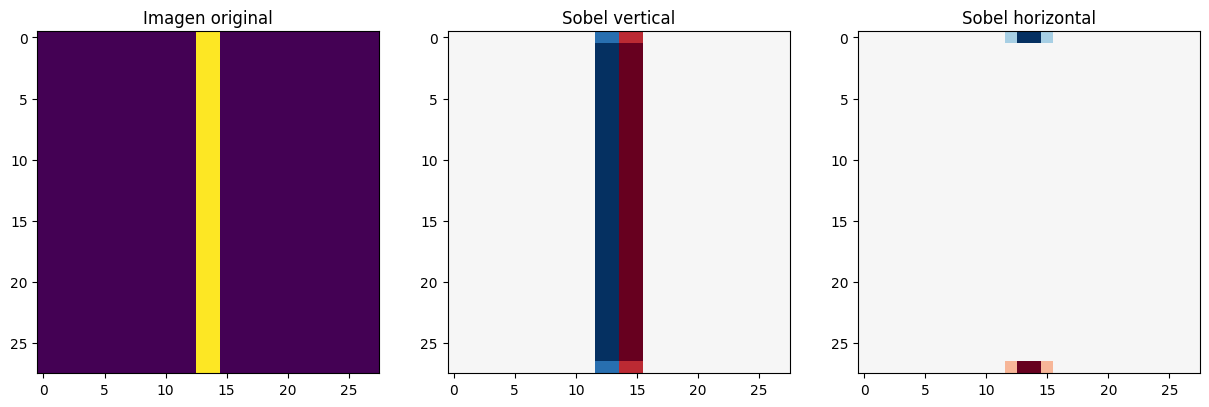

In [2]:
# Implementación manual para entender la operación (sin usar nn.Conv2d)
def conv2d_manual(img, kernel, stride=1, padding=1):
    """
    img: (H, W) tensor
    kernel: (k, k) tensor
    Devuelve: (H_out, W_out)
    """
    k = kernel.shape[0]
    img_p = F.pad(img, (padding,)*4, value=0)
    H, W = img_p.shape
    H_out = (H - k) // stride + 1
    W_out = (W - k) // stride + 1
    out = torch.zeros(H_out, W_out)
    for i in range(H_out):
        for j in range(W_out):
            region = img_p[i*stride:i*stride+k, j*stride:j*stride+k]
            out[i, j] = (region * kernel).sum()
    return out

# Creamos una imagen de prueba (franja vertical blanca en negro)
img = torch.zeros(28, 28)
img[:, 13:15] = 1.0

# Filtro de Sobel vertical (detecta bordes verticales)
sobel_v = torch.tensor([[-1., 0., 1.],
                        [-2., 0., 2.],
                        [-1., 0., 1.]])

# Filtro de Sobel horizontal
sobel_h = torch.tensor([[-1., -2., -1.],
                        [ 0.,  0.,  0.],
                        [ 1.,  2.,  1.]])

out_v = conv2d_manual(img, sobel_v)
out_h = conv2d_manual(img, sobel_h)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img); axes[0].set_title("Imagen original")
axes[1].imshow(out_v, cmap='RdBu'); axes[1].set_title("Sobel vertical")
axes[2].imshow(out_h, cmap='RdBu'); axes[2].set_title("Sobel horizontal")
plt.show()

### 2.1 Max-Pooling

Reduce la dimensión espacial tomando el **máximo** en ventanas de `k × k` con stride `k`:

$$
Y[i,j] = \max_{u,v \in \text{ventana}} X[i \cdot k + u,\; j \cdot k + v]
$$

VGG usa `MaxPool2d(2, 2)`: divide la resolución por 2.

**Efecto:**
- Reduce cómputo y memoria.
- Aumenta la invarianza a pequeñas traslaciones.
- Aumenta el **campo receptivo** efectivo.

### 2.2 ReLU

`f(x) = max(0, x)`. Ventajas:
- No satura para `x > 0` (mejor que sigmoid/tanh).
- Cómputo barato.
- Introduce **sparsity** (activaciones en 0).

### 2.3 Batch Normalization

Normaliza las activaciones de cada canal por mini-batch:

$$
\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \qquad y = \gamma \hat{x} + \beta
$$

- Acelera convergencia (permite learning rates mayores).
- Reduce sensibilidad a la inicialización.
- VGG original **no** usa BN; **VGG16-BN** (versión moderna) sí.

### 2.4 Dropout

Durante el entrenamiento, apaga neuronas con probabilidad `p` y escala las activas por `1/(1-p)`. En VGG se usa `p=0.5` **solo en las capas FC**.

## 4. Arquitectura de VGG16 en detalle

### Tabla de bloques

| Bloque | Capas                                 | Canales | Salida espacial | Pooling |
|--------|----------------------------------------|---------|-----------------|---------|
| Entrada| —                                      | 3       | 224×224         | —       |
| B1     | Conv3-64 · Conv3-64                    | 64      | 224×224         | MaxPool → 112×112 |
| B2     | Conv3-128 · Conv3-128                  | 128     | 112×112         | MaxPool → 56×56  |
| B3     | Conv3-256 · Conv3-256 · Conv3-256      | 256     | 56×56           | MaxPool → 28×28  |
| B4     | Conv3-512 · Conv3-512 · Conv3-512      | 512     | 28×28           | MaxPool → 14×14  |
| B5     | Conv3-512 · Conv3-512 · Conv3-512      | 512     | 14×14           | MaxPool → 7×7    |
| FC1    | Linear 512·7·7 → 4096 + ReLU + Dropout | —       | —               | —       |
| FC2    | Linear 4096 → 4096 + ReLU + Dropout    | —       | —               | —       |
| FC3    | Linear 4096 → 1000 (logits)            | —       | —               | —       |

**Total: 13 capas convolucionales + 3 densas = 16 capas con parámetros** (de ahí el nombre **VGG16**).

### Familia VGG

| Modelo | Conv layers | Capas totales | Params    |
|--------|-------------|---------------|-----------|
| VGG11  | 8           | 11            | ~133 M    |
| VGG13  | 10          | 13            | ~133 M    |
| **VGG16** | **13**   | **16**        | **~138 M**|
| VGG19  | 16          | 19            | ~144 M    |



In [3]:
def make_vgg_block(in_channels, out_channels, num_convs, batch_norm=False):
    """
    Construye un bloque de VGG:
      num_convs × [Conv3x3 - (BN) - ReLU]  seguido de MaxPool2d(2,2)
    - Mantiene la resolución espacial dentro del bloque (padding=1).
    - Reduce a la mitad con el MaxPool final.
    """
    layers = []
    for _ in range(num_convs):
        layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
        if batch_norm:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.ReLU(inplace=True))
        in_channels = out_channels
    layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
    return nn.Sequential(*layers)

# Verificamos formas
x = torch.randn(1, 3, 224, 224)
block = make_vgg_block(3, 64, 2)
y = block(x)
print(f"Entrada: {x.shape} ... Salida bloque1: {y.shape}")
# Esperado: (1, 64, 112, 112)

Entrada: torch.Size([1, 3, 224, 224]) → Salida bloque1: torch.Size([1, 64, 112, 112])


In [4]:
class VGG16(nn.Module):
    def __init__(self, num_classes=1000, in_channels=3, batch_norm=False):
        super().__init__()

        # -------- Extractores de features (bloques convolucionales) --------
        self.block1 = make_vgg_block(in_channels, 64,  2, batch_norm)  # → 112×112
        self.block2 = make_vgg_block(64,         128, 2, batch_norm)  # → 56×56
        self.block3 = make_vgg_block(128,        256, 3, batch_norm)  # → 28×28
        self.block4 = make_vgg_block(256,        512, 3, batch_norm)  # → 14×14
        self.block5 = make_vgg_block(512,        512, 3, batch_norm)  # → 7×7

        # -------- Clasificador (FC) --------
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 7 * 7, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.classifier(x)
        return x

# Verificación
model = VGG16(num_classes=1000).to(device)
x = torch.randn(2, 3, 224, 224).to(device)
logits = model(x)
print(f"Salida: {logits.shape}")  # (2, 1000)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Parámetros totales: {count_parameters(model):,}")

# Desglose
print("\nDesglose por bloque:")
for name, module in model.named_children():
    n = count_parameters(module)
    print(f"  {name:12s}: {n:>12,}  ({100*n/count_parameters(model):5.2f}%)")


Salida: torch.Size([2, 1000])
Parámetros totales: 138,357,544

Desglose por bloque:
  block1      :       38,720  ( 0.03%)
  block2      :      221,440  ( 0.16%)
  block3      :    1,475,328  ( 1.07%)
  block4      :    5,899,776  ( 4.26%)
  block5      :    7,079,424  ( 5.12%)
  classifier  :  123,642,856  (89.36%)


## 5. Campo receptivo (receptive field)

El **campo receptivo** de una neurona es la región de la imagen de entrada que puede influir en su activación.

### Fórmula iterativa

Para una secuencia de capas con kernel `k_i` y stride `s_i`:

$$
RF_1 = k_1, \qquad RF_n = RF_{n-1} + (k_n - 1) \cdot \prod_{i=1}^{n-1} s_i
$$

### Ejemplo: dos conv 3×3 con stride 1

- 1ª conv 3×3: `RF = 3`
- 2ª conv 3×3: `RF = 3 + (3-1)·1 = 5`

Dos conv 3×3 → RF de 5×5 (equivalente a **un solo kernel 5×5**) pero:
- Menos parámetros: `2·9 = 18` vs `25`.
- Una ReLU intermedia.

### En VGG16 (aprox.)

Cada bloque apila convs + un MaxPool 2×2 que **duplica el stride efectivo**.  
Al final de `block5`, el **campo receptivo teórico es de ~212 píxeles**, cada neurona "ve" casi toda la imagen y captura la semántica de alto nivel.

In [5]:
def receptive_field(kernels, strides):
    """
    kernels, strides: listas de igual longitud en orden de aplicación.
    Devuelve RF total.
    """
    rf = 1
    jump = 1
    for k, s in zip(kernels, strides):
        rf = rf + (k - 1) * jump
        jump = jump * s
    return rf

# VGG16: (conv3x3 stride1) * N + (maxpool2x2 stride2) por bloque
# Los bloques: 2+2+3+3+3 = 13 convs 3x3 y 5 pools 2x2
ops = []
for n in [2, 2, 3, 3, 3]:
    ops += [(3, 1)] * n + [(2, 2)]

kernels, strides = zip(*ops)
rf = receptive_field(kernels, strides)
print(f"Campo receptivo teórico al final de VGG16: {rf}×{rf} píxeles")

Campo receptivo teórico al final de VGG16: 212×212 píxeles


## 6. Uso de VGG16 preentrenado (torchvision)

`torchvision.models.vgg16` tiene dos variantes:
- `weights=None`: pesos aleatorios.
- `weights='IMAGENET1K_V1'`: pesos entrenados en ImageNet-1k (1000 clases).
- `weights='IMAGENET1K_V1'` con `batch_norm=True` para VGG16-BN.

### Transformaciones **obligatorias** para usar el modelo

Las imágenes deben pasar por:
1. `Resize(256)` → `CenterCrop(224)` (o directamente `Resize((224,224))`).
2. `ToTensor()`.
3. `Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])` — **medias y std de ImageNet**. Si no se aplica correctamente, el modelo rinde muy por debajo de lo esperado.

In [6]:
from torchvision.models import vgg16, VGG16_Weights

# Carga con pesos de ImageNet
pretrained = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).to(device)
pretrained.eval()
print(f"VGG16 preentrenado cargado. Params: {count_parameters(pretrained):,}")

# Transformaciones de inferencia
inference_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 70.2MB/s]


VGG16 preentrenado cargado. Params: 138,357,544


## 7. Interpretabilidad: filtros y mapas de activación

### 7.1 Filtros de la primera capa
Los filtros de la **primera capa** son interpretables directamente: suelen detectar **bordes orientados, colores opuestos y texturas**

### 7.2 Mapas de activación (feature maps)
Dada una imagen, cada filtro produce un **mapa de activación** que resalta las regiones donde se detecta su patrón.

- **Capas tempranas**: bordes, colores.
- **Capas medias**: texturas, partes.
- **Capas profundas**: objetos completos, semántica.

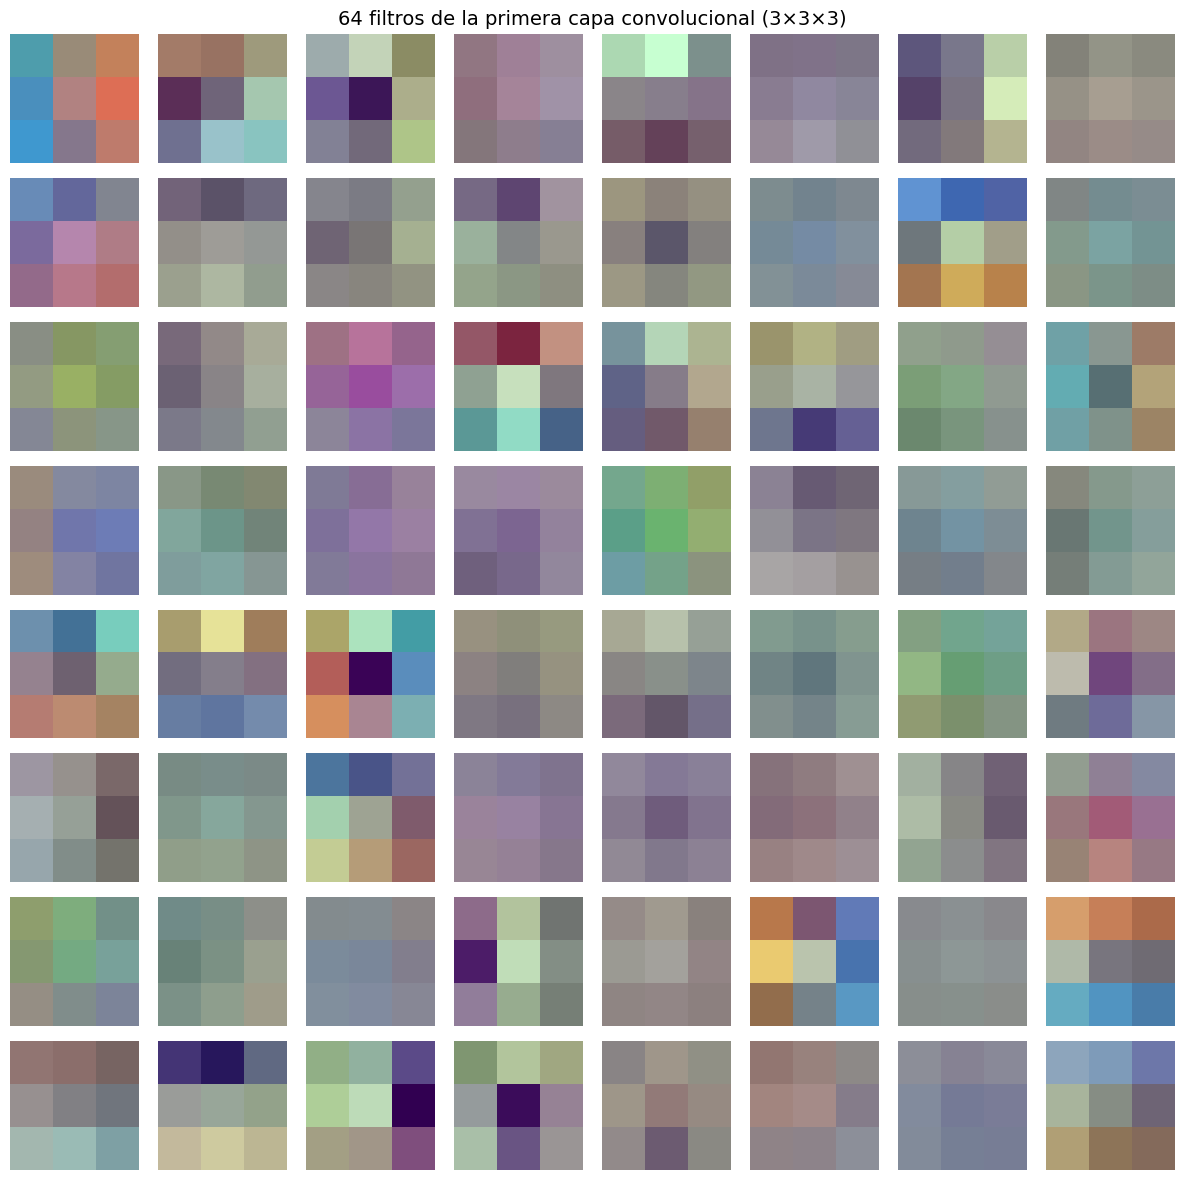

In [7]:
# Filtros de la primera conv: (64, 3, 3, 3)
W = pretrained.features[0].weight.data.cpu()
W_norm = (W - W.min()) / (W.max() - W.min())

fig, axes = plt.subplots(8, 8, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    if i < W_norm.shape[0]:
        ax.imshow(W_norm[i].permute(1, 2, 0))
    ax.axis('off')
plt.suptitle("64 filtros de la primera capa convolucional (3×3×3)", fontsize=14)
plt.tight_layout()
plt.show()

Capa features[0] → shape: (1, 64, 224, 224)
Capa features[4] → shape: (1, 64, 112, 112)
Capa features[11] → shape: (1, 256, 56, 56)
Capa features[18] → shape: (1, 512, 28, 28)
Capa features[25] → shape: (1, 512, 14, 14)


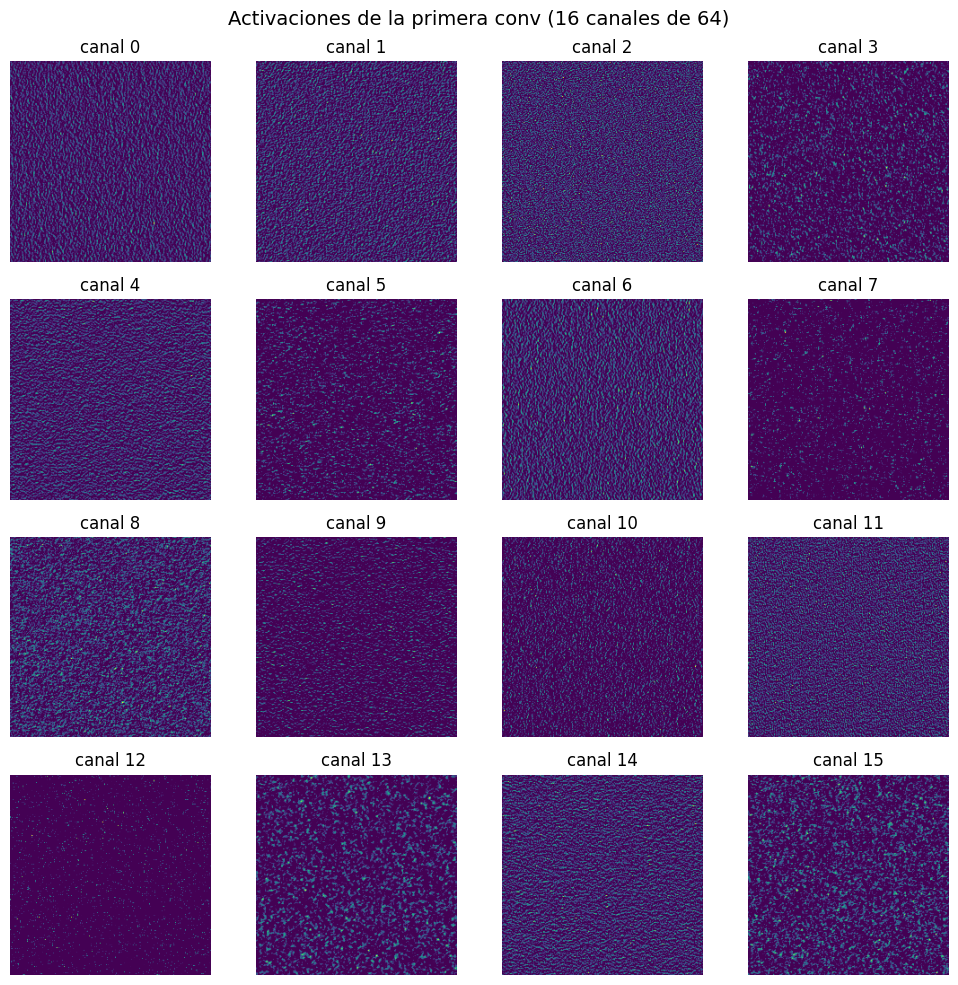

In [8]:
def get_feature_maps(model, x, layer_name):
    """Hook para extraer activaciones de una capa intermedia."""
    feats = {}
    def hook(module, inp, out):
        feats['out'] = out.detach()
    handle = getattr(model.features, layer_name).register_forward_hook(hook)
    model(x)
    handle.remove()
    return feats['out']

# Creamos una imagen sintética (o descarga una real)
img_tensor = torch.randn(1, 3, 224, 224).to(device)

# Extraemos salidas de las 3 primeras convs
for layer_idx in [0, 4, 11, 18, 25]:
    fmap = get_feature_maps(pretrained, img_tensor, str(layer_idx))
    print(f"Capa features[{layer_idx}] → shape: {tuple(fmap.shape)}")

# Visualizamos los primeros 16 mapas de la capa 0
fmap = get_feature_maps(pretrained, img_tensor, "0")[0]  # (64, H, W)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap[i].cpu(), cmap='viridis')
    ax.set_title(f"canal {i}")
    ax.axis('off')
plt.suptitle("Activaciones de la primera conv (16 canales de 64)", fontsize=14)
plt.tight_layout()
plt.show()

## 8. Transfer Learning con VGG16

### Idea
Reemplazar la última FC (clasificador ImageNet de 1000 clases) por un clasificador nuevo. Las features convolucionales son **genéricas** y reutilizables.





In [9]:
from torchvision.models import VGG16_Weights

def build_transfer_model(num_classes=10):
    """VGG16 preentrenado con classifier adaptado a num_classes."""
    model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

    # Congelamos toda la parte convolucional
    for p in model.features.parameters():
        p.requires_grad = False

    # Reemplazamos el clasificador
    in_features = model.classifier[0].in_features  # 25088
    model.classifier = nn.Sequential(
        nn.Linear(in_features, 4096),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(4096, 1024),
        nn.ReLU(inplace=True),
        nn.Dropout(0.3),
        nn.Linear(1024, num_classes),
    )
    return model

tl_model = build_transfer_model(10).to(device)
trainable = sum(p.numel() for p in tl_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in tl_model.parameters())
print(f"Parámetros entrenables: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")

Parámetros entrenables: 106,970,122 / 121,684,810 (87.91%)


### Dataset usado: CIFAR-10

- 60 000 imágenes de 32×32×3, 10 clases.
- Lo **upsampleamos a 224×224** para que entre a VGG16.
- Para la demostración entrenamos solo con un **subconjunto** (para que corra en CPU/GPU modesta). En un caso real, usar el dataset completo.

### Data augmentation
Aplicamos:
- `RandomCrop` tras `Resize(256)` → `RandomHorizontalFlip` → `ColorJitter` suave.
- Esto **reduce overfitting** y **aumenta la robustez**.

> El resize a 224 es caro. Alternativas: adaptar VGG (cambiar FC y quitar algún pool), o fine-tuning solo del primer bloque. Aquí usamos el enfoque estándar con subset para que sea viable.

In [10]:
train_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

test_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

full_train = datasets.CIFAR10(root="./data", train=True,  download=True, transform=train_tf)
full_test  = datasets.CIFAR10(root="./data", train=False, download=True, transform=test_tf)

# Subconjuntos para que entrene rápido en demo (5 000 train / 1 000 test)
train_idx = torch.arange(5000)
test_idx  = torch.arange(1000)
train_ds = Subset(full_train, train_idx)
test_ds  = Subset(full_test,  test_idx)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)

classes = full_train.classes
print(f"Clases: {classes}")
print(f"Train: {len(train_ds)} | Test: {len(test_ds)}")

100%|██████████| 170M/170M [37:46<00:00, 75.2kB/s]


Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train: 5000 | Test: 1000


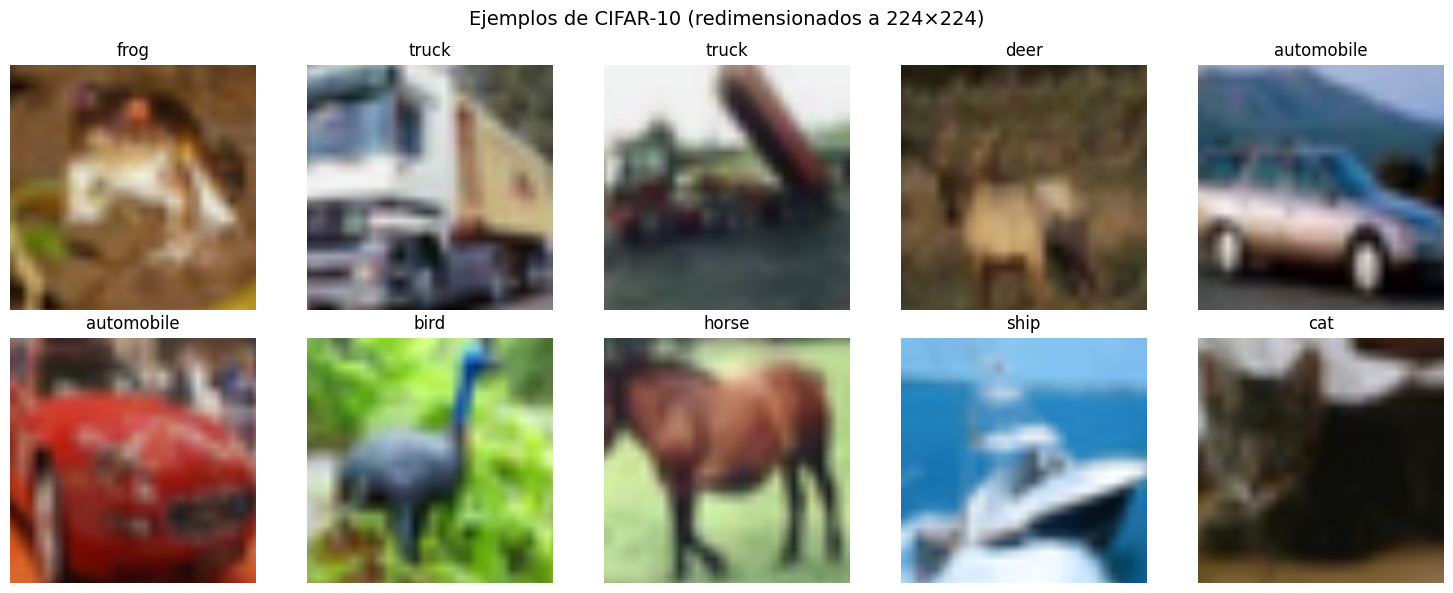

In [11]:
def imshow_normalized(tensor):
    """Desnormaliza y muestra un tensor (C,H,W)."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = tensor * std + mean
    img = img.clamp(0, 1)
    return img.permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    img, label = train_ds[i]
    ax.imshow(imshow_normalized(img))
    ax.set_title(classes[label])
    ax.axis('off')
plt.suptitle("Ejemplos de CIFAR-10 (redimensionados a 224×224)", fontsize=14)
plt.tight_layout()
plt.show()

## 9. Entrenamiento

### Función de pérdida
`CrossEntropyLoss` = `LogSoftmax` + `NLLLoss`. Espera **logits** (sin softmax previo).

$$
\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \log \frac{\exp(z_{y_i})}{\sum_j \exp(z_j)}
$$

### Optimizador
- **SGD con momentum** (típico en VGG): `momentum=0.9`, `weight_decay=5e-4`.
- En transfer learning con features congeladas, **Adam** (1e-3) suele converger más rápido.

### Scheduler
`StepLR(step_size=5, gamma=0.1)` reduce el LR cada 5 epochs.

### Métricas
- Loss en train y validación.
- **Accuracy** en train y validación.
- (Opcional) F1, matriz de confusión, top-5.

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc="train", leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += imgs.size(0)
        pbar.set_postfix(loss=f"{total_loss/total:.4f}", acc=f"{correct/total:.3f}")
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        loss = criterion(logits, labels)
        total_loss += loss.item() * imgs.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total


# Configuración del entrenamiento
NUM_EPOCHS = 5
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, tl_model.parameters()), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc = 0.0
best_state = None

for epoch in range(NUM_EPOCHS):
    tr_loss, tr_acc = train_one_epoch(tl_model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(tl_model, test_loader, criterion, device)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    if va_acc > best_acc:
        best_acc = va_acc
        best_state = copy.deepcopy(tl_model.state_dict())
    print(f"Epoch {epoch+1:02d} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.3f}")

tl_model.load_state_dict(best_state)
print(f"\nMejor val accuracy: {best_acc:.3f}")

Epoch 01 | train loss 1.1278 acc 0.641 | val loss 0.6807 acc 0.773


Epoch 02 | train loss 0.6276 acc 0.791 | val loss 0.5869 acc 0.806


Epoch 03 | train loss 0.5135 acc 0.833 | val loss 0.6456 acc 0.789


Epoch 04 | train loss 0.3609 acc 0.888 | val loss 0.5762 acc 0.829


Epoch 05 | train loss 0.2649 acc 0.912 | val loss 0.6624 acc 0.811

Mejor val accuracy: 0.829


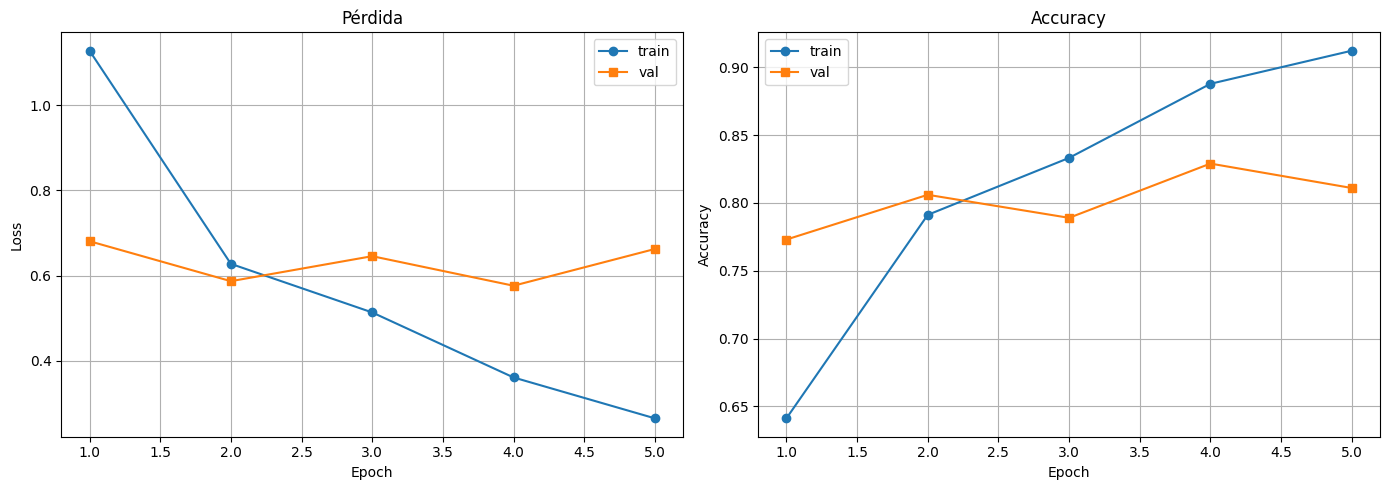

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, NUM_EPOCHS + 1)
axes[0].plot(epochs, history["train_loss"], 'o-', label='train')
axes[0].plot(epochs, history["val_loss"],   's-', label='val')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Pérdida"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(epochs, history["train_acc"], 'o-', label='train')
axes[1].plot(epochs, history["val_acc"],   's-', label='val')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

    airplane      0.744     0.845     0.791       103
  automobile      0.816     0.944     0.875        89
        bird      0.887     0.710     0.789       100
         cat      0.821     0.534     0.647       103
        deer      0.777     0.889     0.829        90
         dog      0.744     0.779     0.761        86
        frog      0.810     0.911     0.857       112
       horse      0.865     0.882     0.874       102
        ship      0.879     0.887     0.883       106
       truck      0.961     0.908     0.934       109

    accuracy                          0.829      1000
   macro avg      0.830     0.829     0.824      1000
weighted avg      0.833     0.829     0.825      1000



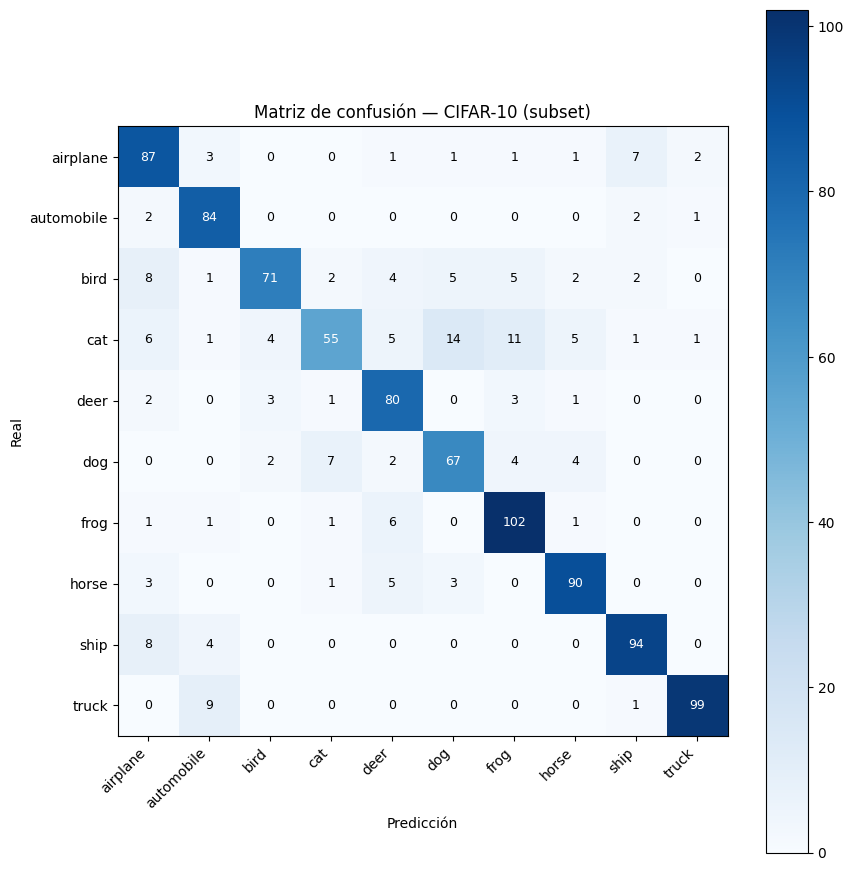

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import itertools

@torch.no_grad()
def collect_preds(model, loader, device):
    model.eval()
    ys, ps = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        preds = model(imgs).argmax(1).cpu().numpy()
        ys.extend(labels.numpy())
        ps.extend(preds)
    return np.array(ys), np.array(ps)

y_true, y_pred = collect_preds(tl_model, test_loader, device)
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10)); ax.set_xticklabels(classes, rotation=45, ha='right')
ax.set_yticks(range(10)); ax.set_yticklabels(classes)
for i, j in itertools.product(range(10), range(10)):
    ax.text(j, i, cm[i, j], ha='center', va='center',
            color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=9)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión — CIFAR-10 (subset)")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

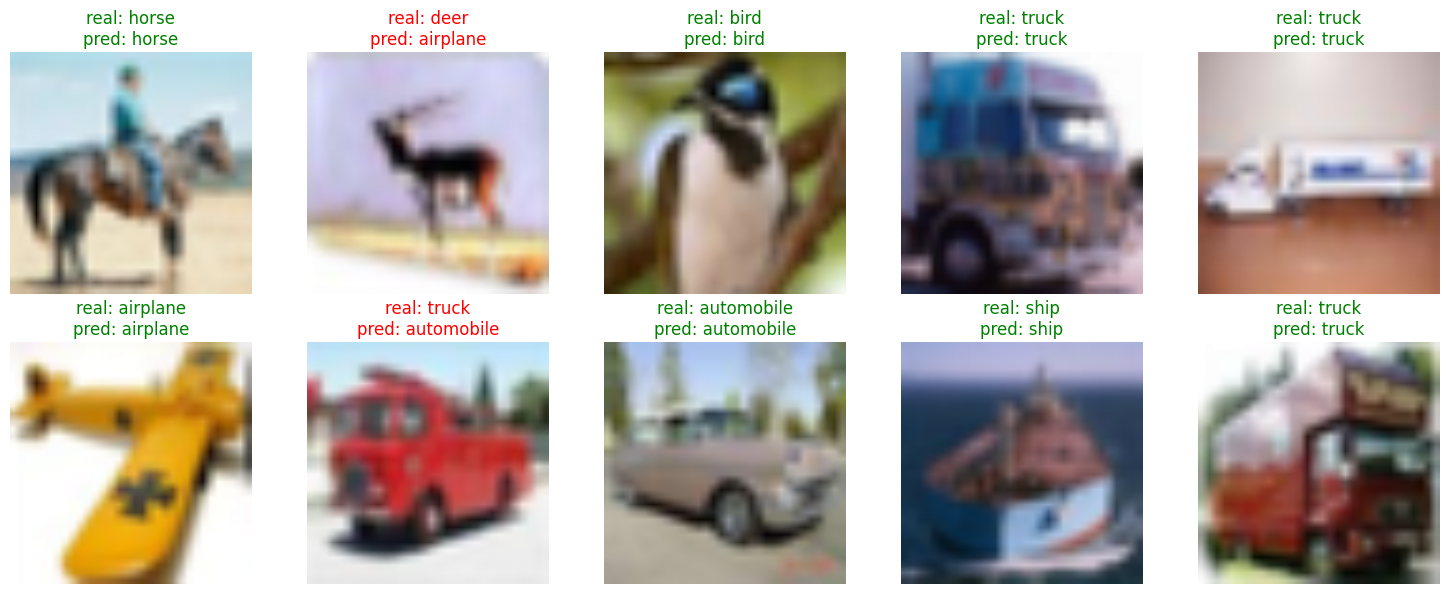

In [15]:
tl_model.eval()
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
idxs = np.random.choice(len(test_ds), 10, replace=False)
for ax, idx in zip(axes.flat, idxs):
    img, label = test_ds[idx]
    with torch.no_grad():
        pred = tl_model(img.unsqueeze(0).to(device)).argmax(1).item()
    ax.imshow(imshow_normalized(img))
    color = 'green' if pred == label else 'red'
    ax.set_title(f"real: {classes[label]}\npred: {classes[pred]}", color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()